# LM12 Lab — Cholesky, SVD and Least Squares

Companion notebook to **From Calculus to Kelly, LM12**. It repairs the sector closes, rebuilds the module's exhibits and computational examples, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 0 | Data: the served sector closes, the repair cell (rule and counts), returns and the common sample |
| 1 | Least squares as a projection: Example 1, Example 2, $\Pi^2=\Pi$, orthogonality, R-squared as $\cos^2\theta$ |
| 2 | Rebuilding TAIEX: the case (Exhibit 1), the last 250 returns (Example 3, Exhibit 3), one fit per year (Example 4, Exhibit 4) and the widget's table |
| 3 | The SVD: Example 5 against `np.linalg.svd`, $\lambda_k=s_k^2$, conditioning (Example 6, Exhibit 6) |
| 4 | December 2008 (Example 7, Exhibit 7); numerical rank at three tolerances (Example 8, Exhibit 8) |
| 5 | Cholesky: the recursion (12.8) against `np.linalg.cholesky`, sequential regressions (Example 9, Exhibit 9), `LinAlgError` |
| 6 | Whitening and colouring: 7 April 2025 (Example 10, Exhibit 10, Exhibit 11), the asset order |
| 7 | Practice problems 3–12 and an extension exercise |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `sectors_close_raw.csv` (the closes FinMind's `TaiwanStockPrice` serves for TAIEX and the 30 TWSE sector indices, one column per series, empty where a series has no close) and `sectors_close_repairs.csv` (each of the 561 closes that FinMind copied from another date or series, with its official 13:30:00 value from `TaiwanStockEvery5SecondsIndex`). The notebook reads nothing outside `data/`.

**Conventions (as in the module).** Daily simple returns of price indices between consecutive TAIEX-calendar dates; the common sample of TAIEX and U28 (the 28 sector indices without the aggregates Electronic and ChemicalBiotechnologyMedicalCare) from the close of 2008-12-01 to 2026-10-08, $T=4{,}382$ returns; moments divide by $T$; a fit is least squares of TAIEX's returns on the sector returns with an intercept. Every fit is in-sample, the yearly fits are a stability check, and the SVD, $L$ and $\mathbf z_t$ describe the full sample.

In [1]:
from pathlib import Path
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
FIRST_CLOSE, LAST_CLOSE = "2008-12-01", "2026-10-08"
AGGREGATES = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
S3 = ["Semiconductor", "FinancialInsurance", "Food"]
S5 = S3 + ["Plastics", "ShippingTransportation"]
ELEC8 = ["Semiconductor", "ComputerPeripheralEquipment", "Optoelectronic", "CommunicationsInternet",
         "ElectronicPartsComponents", "ElectronicProductsDistribution", "InformationService", "OtherElectronic"]
pl.Config.set_tbl_rows(40)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

## Part 0 — Data and the repair cell

FinMind's `TaiwanStockPrice` serves the sector indices with some rows copied from another date, or from another series on the same date (PITFALLS §3 of the repository). The book replaces each of these 561 closes with the official 13:30:00 value. On FinMind's free plan the 13:30:00 values are not available (`TaiwanStockEvery5SecondsIndex` is a paid dataset), so `close_1330` is empty and the cell **drops** those closes instead: a dropped close removes the returns into and out of its date, and the common sample shrinks from 4,382 to 4,307 returns. Nothing is ever estimated.

In [2]:
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
series = [c for c in raw.columns if c != "date"]
fixed = raw
for sid in rep["id"].unique(maintain_order=True).to_list():
    g = rep.filter(pl.col("id") == pl.lit(sid)).select("date", pl.col("close_1330").alias("_new"),
                                                        pl.lit(True).alias("_listed"))
    fixed = (fixed.join(g, on="date", how="left").sort("date")
                  .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
                  .drop("_new", "_listed"))
n_listed = rep.height
n_replaced = int(rep["close_1330"].is_not_null().sum())
U28 = [c for c in series if c not in ("TAIEX", *AGGREGATES)]
in_sample = rep.filter((pl.col("date") >= pl.lit(FIRST_CLOSE)) & pl.col("id").is_in(U28))
elec = rep.filter((pl.col("date") >= pl.lit(FIRST_CLOSE)) & (pl.col("id") == pl.lit("Electronic")))
FULL_DATA = n_replaced == n_listed
print("Rule: every close listed in sectors_close_repairs.csv is replaced by its 13:30:00 value (close_1330);")
print("      a listed close without that value is dropped (set to missing), never estimated.")
print(f"listed closes {n_listed}: replaced {n_replaced}, dropped {n_listed - n_replaced}")
print(f"in this module's sample (U28 from {FIRST_CLOSE}): {in_sample.height} closes on {in_sample['date'].n_unique()} dates; "
      f"Electronic adds {elec.height} on dates among them")

Rule: every close listed in sectors_close_repairs.csv is replaced by its 13:30:00 value (close_1330);
      a listed close without that value is dropped (set to missing), never estimated.
listed closes 561: replaced 561, dropped 0
in this module's sample (U28 from 2008-12-01): 524 closes on 38 dates; Electronic adds 18 on dates among them


In [3]:
ret = (fixed.filter(pl.col("date").is_between(pl.lit(FIRST_CLOSE), pl.lit(LAST_CLOSE))).sort("date")
            .with_columns([(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in series])
            .with_columns(pl.col("date").shift(1).alias("prev"))
            .slice(1))
smp = ret.filter(pl.all_horizontal([pl.col(c).is_not_null() for c in ["TAIEX", *U28]]))
T = smp.height
dates = smp["date"].to_list()
X = smp.select(U28).to_numpy()
y = smp["TAIEX"].to_numpy()
year = np.array([int(d[:4]) for d in dates])
col = {c: i for i, c in enumerate(U28)}
print(f"common sample: T = {T} returns, {dates[0]} .. {dates[-1]}; X is {X.shape}, y is {y.shape}")
assert smp.select(AGGREGATES).null_count().row(0) == (0, 0)


def show(label, value, fmt, printed, kept=False):
    # print a value next to the module's printed value; assert equality when every close is repaired, or when the
    # number comes from a window without a listed close (December 2008, the last 250 returns, 2014, 2023, 2024, 2026)
    got = format(value, fmt)
    note = "" if got == printed else ("   (differs: closes were dropped)" if not (FULL_DATA or kept) else "   MISMATCH")
    print(f"{label}: {got}   [book: {printed}]{note}")
    if FULL_DATA or kept:
        assert got == printed, (label, got, printed)


show("T", T, ",", "4,382")

common sample: T = 4382 returns, 2008-12-02 .. 2026-10-08; X is (4382, 28), y is (4382,)
T: 4,382   [book: 4,382]


**Which numbers change on the free plan.** With the 561 listed closes dropped, the sample keeps $T=4{,}307$ returns. Numbers computed inside a window without a listed close keep their values: December 2008, the last 250 returns, the calendar years 2014, 2023, 2024 and 2026, and the raw returns of 7–10 April 2025. Everything that uses the full sample changes slightly: the full-sample fit and the other yearly fits, the SVD and condition numbers of the full sample and of 2016, the Cholesky factors, the whitened returns and the ranking of days. The mean of $\lVert\mathbf z_t\rVert^2$ stays exactly $N$. `show(...)` prints each value next to the module's and asserts equality only where the value cannot change.

## Part 1 — Least squares as a projection

**Example 1.** The multiple of $\mathbf x=(2,1)^{\top}$ closest to $\mathbf y=(1,3)^{\top}$. **Example 2.** A line through four points, with and without an intercept (the pitfall of Section 2). Then the projection matrix (12.2) on real data: the last 250 returns with an intercept.

In [4]:
x1, y1 = np.array([2.0, 1.0]), np.array([1.0, 3.0])
b1 = x1 @ y1 / (x1 @ x1)
print(f"Example 1: beta = {b1}, fitted {b1 * x1}, residual {y1 - b1 * x1}, x'e = {x1 @ (y1 - b1 * x1)}, "
      f"distance {np.linalg.norm(y1 - b1 * x1):.3f}; 1.5x is at {np.linalg.norm(y1 - 1.5 * x1):.1f}")

x4, y4 = np.array([0.0, 1, 2, 3]), np.array([1.0, 3, 2, 6])
D4 = np.column_stack([np.ones(4), x4])
a4, b4 = np.linalg.lstsq(D4, y4, rcond=None)[0]
e4 = y4 - D4 @ np.array([a4, b4])
yc = y4 - y4.mean()
print(f"Example 2: alpha = {a4:.1f}, beta = {b4:.1f}, residuals {e4.round(1)}, sum {e4.sum():.1e}, x'e {x4 @ e4:.1e}")
print(f"   R-squared = 1 - {e4 @ e4:.1f}/{yc @ yc:.0f} = {1 - e4 @ e4 / (yc @ yc):.1f}; squared cosine "
      f"{(np.corrcoef(x4, y4)[0, 1]) ** 2:.1f}")
b0 = x4 @ y4 / (x4 @ x4)
e0 = y4 - b0 * x4
print(f"   through the origin: beta = {b0:.3f}, |e|^2 = {e0 @ e0:.3f}, uncentred share {1 - e0 @ e0 / (y4 @ y4):.3f}, "
      f"centred formula {1 - e0 @ e0 / (yc @ yc):.3f}")

Example 1: beta = 1.0, fitted [2. 1.], residual [-1.  2.], x'e = 0.0, distance 2.236; 1.5x is at 2.5
Example 2: alpha = 0.9, beta = 1.4, residuals [ 0.1  0.7 -1.7  0.9], sum 3.0e-15, x'e 5.8e-15
   R-squared = 1 - 4.2/14 = 0.7; squared cosine 0.7
   through the origin: beta = 1.786, |e|^2 = 5.357, uncentred share 0.893, centred formula 0.617


In [5]:
LAST = np.arange(T) >= T - 250
D = np.column_stack([np.ones(250), X[LAST]])
Pi = D @ np.linalg.solve(D.T @ D, D.T)            # projection matrix (12.2), 250 x 250; solve, never inv
yl = y[LAST]
e = yl - Pi @ yl
print(f"last 250 design {D.shape}: |Pi Pi - Pi| = {np.abs(Pi @ Pi - Pi).max():.1e}, |Pi - Pi'| = {np.abs(Pi - Pi.T).max():.1e}, "
      f"trace = {np.trace(Pi):.6f}, max |D'e| = {np.abs(D.T @ e).max():.1e}")
fit_c = Pi @ yl - yl.mean()
cos = (yl - yl.mean()) @ fit_c / (np.linalg.norm(yl - yl.mean()) * np.linalg.norm(fit_c))
show("R-squared, last 250, as 1 - |e|^2/|y~|^2", 1 - e @ e / ((yl - yl.mean()) @ (yl - yl.mean())), ".5f", "0.99912", kept=True)
show("R-squared, last 250, as cos^2 theta", cos**2, ".5f", "0.99912", kept=True)

last 250 design (250, 29): |Pi Pi - Pi| = 2.8e-16, |Pi - Pi'| = 3.2e-16, trace = 29.000000, max |D'e| = 4.4e-17
R-squared, last 250, as 1 - |e|^2/|y~|^2: 0.99912   [book: 0.99912]
R-squared, last 250, as cos^2 theta: 0.99912   [book: 0.99912]


## Part 2 — Rebuilding TAIEX from its sectors

`fit(mask)` regresses TAIEX on the 28 sector returns with an intercept on the dates in `mask` (`np.linalg.lstsq` on $(\mathbf 1\ X)$, which returns the minimum-norm solution when the design is rank deficient).

In [6]:
def fit(mask):
    D = np.column_stack([np.ones(int(mask.sum())), X[mask]])
    b = np.linalg.lstsq(D, y[mask], rcond=None)[0]
    e = y[mask] - D @ b
    yc = y[mask] - y[mask].mean()
    return b, 1 - e @ e / (yc @ yc), np.linalg.matrix_rank(D)


FULL = np.ones(T, dtype=bool)
DEC = np.array([d.startswith("2008-12") for d in dates])
SIX = ["Semiconductor", "ElectronicPartsComponents", "FinancialInsurance", "ComputerPeripheralEquipment",
       "OtherElectronic", "CommunicationsInternet"]
fits = {"full sample": fit(FULL), "last 250": fit(LAST), "December 2008": fit(DEC)}
case = pl.DataFrame([{"sample": k, "T": int(m.sum()), "rank": int(f[2]), "R-squared": f[1], "sum of slopes": f[0][1:].sum(),
                      **{c: f[0][1 + col[c]] for c in SIX}} for (k, f), m in zip(fits.items(), (FULL, LAST, DEC))])
case   # Exhibit 1

sample,T,rank,R-squared,sum of slopes,Semiconductor,ElectronicPartsComponents,FinancialInsurance,ComputerPeripheralEquipment,OtherElectronic,CommunicationsInternet
str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""full sample""",4382,29,0.983326,1.009356,0.337425,0.080627,0.123193,0.067493,0.059575,0.074722
"""last 250""",250,29,0.999121,0.990335,0.542284,0.097593,0.083770,0.054491,0.046945,0.038280
"""December 2008""",22,22,1.000000,0.968433,0.145008,0.065452,0.165282,0.060467,0.054883,0.080514


Example 3 R-squared: 0.99912   [book: 0.99912]
   Semiconductor: 0.542   [book: 0.542]
   ElectronicPartsComponents: 0.098   [book: 0.098]
   FinancialInsurance: 0.084   [book: 0.084]
   ComputerPeripheralEquipment: 0.054   [book: 0.054]
   OtherElectronic: 0.047   [book: 0.047]
   CommunicationsInternet: 0.038   [book: 0.038]
   sum of the 28 slopes: 0.990   [book: 0.990]
   intercept, % a day: -0.013   [book: -0.013]
   negative coefficients: 7   [book: 7]
   smallest (InformationService): -0.0081   [book: -0.0081]
   R-squared without Semiconductor: 0.856   [book: 0.856]
full sample R-squared: 0.98333   [book: 0.98333]


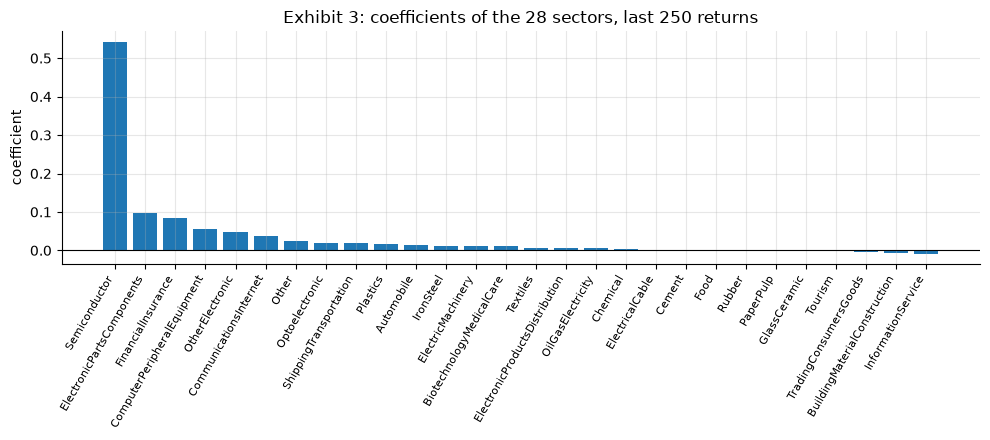

In [7]:
b_last, r2_last, _ = fits["last 250"]
show("Example 3 R-squared", r2_last, ".5f", "0.99912", kept=True)
for c, p in zip(SIX, ("0.542", "0.098", "0.084", "0.054", "0.047", "0.038")):
    show(f"   {c}", b_last[1 + col[c]], ".3f", p, kept=True)
show("   sum of the 28 slopes", b_last[1:].sum(), ".3f", "0.990", kept=True)
show("   intercept, % a day", 100 * b_last[0], ".3f", "-0.013", kept=True)
show("   negative coefficients", int((b_last[1:] < 0).sum()), "d", "7", kept=True)
show(f"   smallest ({U28[int(np.argmin(b_last[1:]))]})", b_last[1:].min(), ".4f", "-0.0081", kept=True)
Xw = np.delete(X, col["Semiconductor"], axis=1)
Dw = np.column_stack([np.ones(250), Xw[LAST]])
ew = y[LAST] - Dw @ np.linalg.lstsq(Dw, y[LAST], rcond=None)[0]
show("   R-squared without Semiconductor", 1 - ew @ ew / ((y[LAST] - y[LAST].mean()) ** 2).sum(), ".3f", "0.856", kept=True)
show("full sample R-squared", fits["full sample"][1], ".5f", "0.98333")

order = np.argsort(-b_last[1:], kind="stable")
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(28), b_last[1:][order], color="tab:blue")
ax.set_xticks(range(28), [U28[i] for i in order], rotation=60, ha="right", fontsize=8)
ax.axhline(0, color="black", lw=0.8); ax.set_ylabel("coefficient")
ax.set_title("Exhibit 3: coefficients of the 28 sectors, last 250 returns"); plt.tight_layout(); plt.show()

In [8]:
KEPT_YEARS = (2014, 2023, 2024, 2026)          # no listed close inside these years
rows = []
for yr in range(2009, 2027):
    b, r2, _ = fit(year == yr)
    rows.append({"year": yr, "T": int((year == yr).sum()), "R-squared": r2, "sum": b[1:].sum(),
                 **{c: b[1 + col[c]] for c in SIX[:4]}, "negatives": int((b[1:] < 0).sum())})
yearly = pl.DataFrame(rows)
print("the widget's table: one fit per calendar year (2026 to 8 October)")
yearly

the widget's table: one fit per calendar year (2026 to 8 October)


year,T,R-squared,sum,Semiconductor,ElectronicPartsComponents,FinancialInsurance,ComputerPeripheralEquipment,negatives
i64,i64,f64,f64,f64,f64,f64,f64,i64
2009,251,0.999594,1.007848,0.189227,0.035505,0.132874,0.076267,0
2010,251,0.999621,1.001107,0.174678,0.048857,0.128716,0.076020,0
2011,247,0.999695,0.993860,0.165462,0.039678,0.132671,0.069357,0
2012,250,0.999879,0.996308,0.181653,0.042641,0.123821,0.071755,0
2013,246,0.999829,0.999192,0.196975,0.040810,0.138814,0.062868,0
2014,248,0.999679,0.998936,0.218000,0.043430,0.137327,0.065551,0
2015,244,0.999843,0.996330,0.224062,0.046360,0.147527,0.059518,1
2016,244,0.999917,1.003628,0.240266,0.045118,0.129984,0.058851,0
2017,246,0.999608,1.003699,0.257993,0.042294,0.128685,0.056763,0


Example 4 Semiconductor 2009: 0.189   [book: 0.189]
   Semiconductor 2026: 0.554   [book: 0.554]
   FinancialInsurance 2009: 0.133   [book: 0.133]
   FinancialInsurance 2026: 0.080   [book: 0.080]
   smallest yearly R-squared (2021): 0.99800   [book: 0.99800]
   every year above the full sample: True


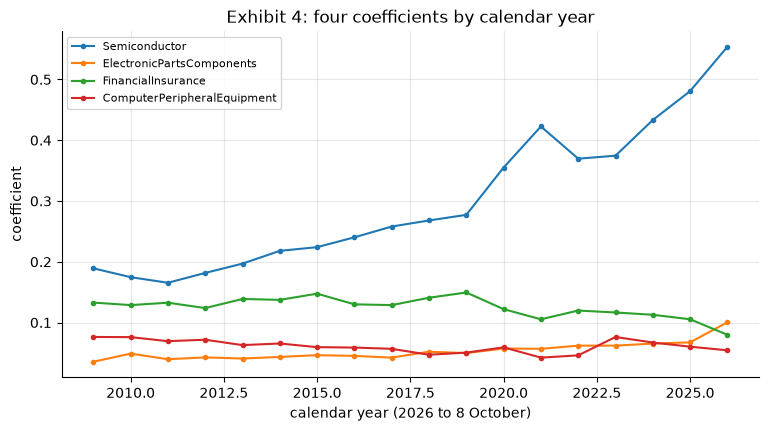

In [9]:
yr_ = {r["year"]: r for r in rows}
show("Example 4 Semiconductor 2009", yr_[2009]["Semiconductor"], ".3f", "0.189")
show("   Semiconductor 2026", yr_[2026]["Semiconductor"], ".3f", "0.554", kept=True)
show("   FinancialInsurance 2009", yr_[2009]["FinancialInsurance"], ".3f", "0.133")
show("   FinancialInsurance 2026", yr_[2026]["FinancialInsurance"], ".3f", "0.080", kept=True)
low = min(rows, key=lambda r: r["R-squared"])
show(f"   smallest yearly R-squared ({low['year']})", low["R-squared"], ".5f", "0.99800")
print("   every year above the full sample:", all(r["R-squared"] > fits["full sample"][1] for r in rows))
fig, ax = plt.subplots()
for c in SIX[:4]:
    ax.plot(yearly["year"], yearly[c], marker="o", ms=3, label=c)
ax.set_xlabel("calendar year (2026 to 8 October)"); ax.set_ylabel("coefficient")
ax.set_title("Exhibit 4: four coefficients by calendar year"); ax.legend(fontsize=8); plt.show()

## Part 3 — The singular value decomposition

**Example 5.** `np.linalg.svd` returns $U$, the singular values in **descending** order and $V^{\top}$ (as `Vh`, whose rows are the $\mathbf v_k$); `np.linalg.eigh` returns eigenvalues in **ascending** order. The book signs each $\mathbf v_k$ so that its entry largest in absolute value is positive (the first of tied entries) and then sets $\mathbf u_k=M\mathbf v_k/s_k$.

In [10]:
def sign_rule(v):
    a = np.abs(v)
    k = int(np.flatnonzero(a >= a.max() - 1e-12)[0])
    return v if v[k] > 0 else -v


M = np.array([[4.0, 4.0], [-2.0, 4.0]])
U, s, Vh = np.linalg.svd(M)
v = [sign_rule(r) for r in Vh]
u = [M @ v[k] / s[k] for k in range(2)]
print("M'M =", (M.T @ M).tolist(), " eigenvalues (eigh, ascending):", np.linalg.eigh(M.T @ M)[0])
print("singular values:", s, " v_1, v_2 * sqrt(5):", (np.array(v) * math.sqrt(5)).round(6).tolist(),
      " u_1, u_2 * sqrt(5):", (np.array(u) * math.sqrt(5)).round(6).tolist())
print(f"|det M| = {abs(np.linalg.det(M)):.6f} = s_1 s_2 = {s[0] * s[1]:.6f}; kappa = {np.linalg.cond(M):.2f}")

M'M = [[20.0, 8.0], [8.0, 32.0]]  eigenvalues (eigh, ascending): [16. 36.]
singular values: [6. 4.]  v_1, v_2 * sqrt(5): [[1.0, 2.0], [2.0, -1.0]]  u_1, u_2 * sqrt(5): [[2.0, 1.0], [1.0, -2.0]]
|det M| = 24.000000 = s_1 s_2 = 24.000000; kappa = 1.50


In [11]:
Xc = X - X.mean(axis=0)
sv = np.linalg.svd(Xc / math.sqrt(T), compute_uv=False)
Sig = Xc.T @ Xc / T
lam = np.linalg.eigh(Sig)[0][::-1]
print(f"lambda_k = s_k^2 for U28: largest gap {np.abs(lam - sv ** 2).max():.1e}")
show("Example 6 s_1", sv[0], ".6f", "0.054245")
show("   s_28", sv[-1], ".6f", "0.005218")
show("   kappa(X~)", sv[0] / sv[-1], ".2f", "10.40")
show("   kappa(Sigma) = kappa(X~)^2", (sv[0] / sv[-1]) ** 2, ".2f", "108.09")
print(f"   np.linalg.cond(Sigma) = {np.linalg.cond(Sig):.2f}")


def solvers(cols, mask):
    Z = smp.filter(pl.Series(mask)).select(cols).to_numpy()
    Zc, yc = Z - Z.mean(axis=0), y[mask] - y[mask].mean()
    s_ = np.linalg.svd(Zc, compute_uv=False)
    gap = np.abs(np.linalg.lstsq(Zc, yc, rcond=None)[0] - np.linalg.solve(Zc.T @ Zc, Zc.T @ yc)).max()
    return s_[0] / s_[-1], np.linalg.cond(Zc.T @ Zc), gap


cond_rows = [("S3, full sample", S3, FULL), ("S5, full sample", S5, FULL), ("U28, full sample", U28, FULL),
             ("U28, last 250 returns", U28, LAST), ("U28 + Electronic, full sample", ["Electronic", *U28], FULL),
             ("U28 + Electronic, 2016", ["Electronic", *U28], year == 2016)]
tbl = []
for name, cols, mask in cond_rows:
    k1, k2, gap = solvers(cols, mask)
    tbl.append({"design": name, "columns": len(cols), "kappa(X~)": k1, "kappa(X~'X~)": k2,
                "gap order": f"1e{math.floor(math.log10(gap))}" if gap > 0 else "0",
                "digits lost (rule of thumb)": math.log10(k2)})
pl.DataFrame(tbl)   # Exhibit 6; the gap depends on the machine, only its order matters

lambda_k = s_k^2 for U28: largest gap 8.7e-19
Example 6 s_1: 0.054245   [book: 0.054245]
   s_28: 0.005218   [book: 0.005218]
   kappa(X~): 10.40   [book: 10.40]
   kappa(Sigma) = kappa(X~)^2: 108.09   [book: 108.09]
   np.linalg.cond(Sigma) = 108.09


design,columns,kappa(X~),kappa(X~'X~),gap order,digits lost (rule of thumb)
str,i64,f64,f64,str,f64
"""S3, full sample""",3,2.654220,7.044883,"""1e-16""",0.847874
"""S5, full sample""",5,3.481043,12.117659,"""1e-16""",1.083419
"""U28, full sample""",28,10.396403,108.085202,"""1e-16""",2.033766
"""U28, last 250 returns""",28,17.035447,290.206471,"""1e-15""",2.462707
"""U28 + Electronic, full sample""",29,48.329877,2335.777014,"""1e-15""",3.368431
"""U28 + Electronic, 2016""",29,642.002063,412166.649514,"""1e-12""",5.615073


## Part 4 — Rank deficiency, the pseudoinverse and numerical rank

**Example 7.** December 2008: 22 returns, 29 coefficients. `lstsq` and `pinv` return the minimum-norm solution (12.7). Note that `lstsq` returns an empty array of residual sums when the design is rank deficient. **Example 8.** The numerical rank of Electronic and its eight sub-industries at three tolerances.

In [12]:
D8 = np.column_stack([np.ones(int(DEC.sum())), X[DEC]])
sol = np.linalg.lstsq(D8, y[DEC], rcond=None)
b_pinv = np.linalg.pinv(D8) @ y[DEC]
print(f"design {D8.shape}, matrix_rank {np.linalg.matrix_rank(D8)}, null space dimension {D8.shape[1] - np.linalg.matrix_rank(D8)}; "
      f"lstsq residual sums: {sol[1]} (empty when rank deficient); |lstsq - pinv| = {np.abs(sol[0] - b_pinv).max():.1e}")
print(f"largest |residual| {np.abs(y[DEC] - D8 @ b_pinv).max():.1e} (below 1e-13)")
show("minimum-norm: Semiconductor", b_pinv[1 + col["Semiconductor"]], ".3f", "0.145", kept=True)
show("   FinancialInsurance", b_pinv[1 + col["FinancialInsurance"]], ".3f", "0.165", kept=True)
show("   norm of the 29 coefficients", np.linalg.norm(b_pinv), ".3f", "0.285", kept=True)
D8w = np.delete(D8, 1 + col["Semiconductor"], axis=1)
names_w = ["intercept"] + [c for c in U28 if c != "Semiconductor"]
b_w = np.linalg.pinv(D8w) @ y[DEC]
print(f"without Semiconductor: rank {np.linalg.matrix_rank(D8w)}, largest |residual| {np.abs(y[DEC] - D8w @ b_w).max():.1e}")
show("   FinancialInsurance", b_w[names_w.index("FinancialInsurance")], ".3f", "0.218", kept=True)
show("   norm", np.linalg.norm(b_w), ".3f", "0.401", kept=True)
pl.DataFrame({"coefficient": ["intercept", *U28],
              "all 28 sectors": b_pinv,
              "without Semiconductor": np.insert(b_w, 1 + col["Semiconductor"], np.nan)})   # Exhibit 7

design (22, 29), matrix_rank 22, null space dimension 7; lstsq residual sums: [] (empty when rank deficient); |lstsq - pinv| = 5.5e-16
largest |residual| 6.2e-17 (below 1e-13)
minimum-norm: Semiconductor: 0.145   [book: 0.145]
   FinancialInsurance: 0.165   [book: 0.165]
   norm of the 29 coefficients: 0.285   [book: 0.285]
without Semiconductor: rank 22, largest |residual| 2.0e-15
   FinancialInsurance: 0.218   [book: 0.218]
   norm: 0.401   [book: 0.401]


coefficient,all 28 sectors,without Semiconductor
str,f64,f64
"""intercept""",-0.000263,-0.000726
"""Automobile""",0.010101,0.016900
"""BiotechnologyMedicalCare""",0.011561,0.038622
"""BuildingMaterialConstruction""",0.014706,0.052839
"""Cement""",0.036484,0.028294
"""Chemical""",0.009912,0.030583
"""CommunicationsInternet""",0.080514,0.067701
"""ComputerPeripheralEquipment""",0.060467,0.045921
"""ElectricMachinery""",-0.008309,-0.126957


s_9/s_1 standardized, full sample: 0.0346   [book: 0.0346]
s_9/s_1 standardized, 2016: 0.00277   [book: 0.00277]
s_9/s_1 covariance scale, full sample: 0.0329   [book: 0.0329]
delta = 0.1: numerical rank 8 (full sample), 8 (2016)
delta = 0.01: numerical rank 9 (full sample), 8 (2016)
delta = 0.001: numerical rank 9 (full sample), 9 (2016)


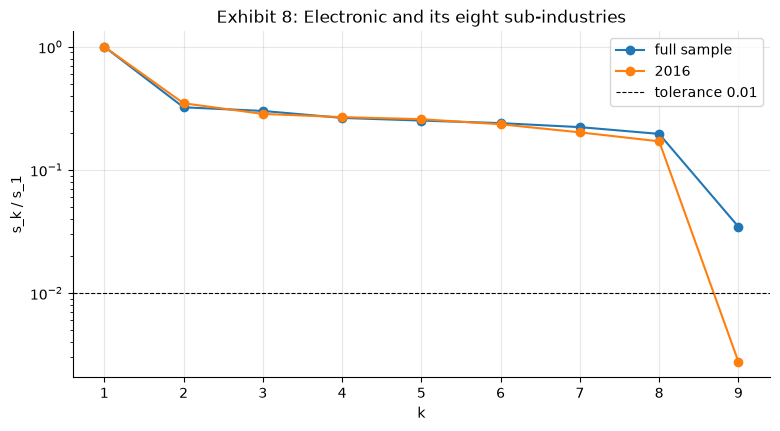

In [13]:
E9 = smp.select(["Electronic", *ELEC8]).to_numpy()


def ratios(mask, standardize=True):
    Z = E9[mask] - E9[mask].mean(axis=0)
    if standardize:
        Z = Z / Z.std(axis=0)
    s_ = np.linalg.svd(Z / math.sqrt(int(mask.sum())), compute_uv=False)
    return s_ / s_[0]


r_full, r_2016 = ratios(FULL), ratios(year == 2016)
show("s_9/s_1 standardized, full sample", r_full[-1], ".4f", "0.0346")
show("s_9/s_1 standardized, 2016", r_2016[-1], ".5f", "0.00277")
show("s_9/s_1 covariance scale, full sample", ratios(FULL, False)[-1], ".4f", "0.0329")
for delta in (0.1, 0.01, 0.001):
    print(f"delta = {delta}: numerical rank {int((r_full > delta).sum())} (full sample), {int((r_2016 > delta).sum())} (2016)")
fig, ax = plt.subplots()
ax.semilogy(range(1, 10), r_full, marker="o", label="full sample")
ax.semilogy(range(1, 10), r_2016, marker="o", label="2016")
ax.axhline(0.01, color="black", ls="--", lw=0.8, label="tolerance 0.01")
ax.set_xlabel("k"); ax.set_ylabel("s_k / s_1"); ax.set_title("Exhibit 8: Electronic and its eight sub-industries")
ax.legend(); plt.show()

## Part 5 — Cholesky: the recursion, sequential regressions and failure

The recursion (12.8) column by column, checked against `np.linalg.cholesky` (lower factor). `scipy.linalg.cholesky` returns the **upper** factor by default.

In [14]:
def cholesky(S):
    n = len(S)
    L = np.zeros_like(S)
    for j in range(n):
        d = S[j, j] - L[j, :j] @ L[j, :j]
        if d <= 0:
            raise np.linalg.LinAlgError(f"not positive definite at column {j + 1}")
        L[j, j] = math.sqrt(d)
        for i in range(j + 1, n):
            L[i, j] = (S[i, j] - L[i, :j] @ L[j, :j]) / L[j, j]
    return L


i5 = [col[c] for c in S5]
S5m = Sig[np.ix_(i5, i5)]
L5 = cholesky(S5m)
print(f"own recursion vs np.linalg.cholesky: largest difference {np.abs(L5 - np.linalg.cholesky(S5m)).max():.1e}")
show("Example 9 sigma_11 (x 1e4)", 1e4 * S5m[0, 0], ".6f", "2.323354")
show("   l_11", L5[0, 0], ".7f", "0.0152426")
show("   l_21", L5[1, 0], ".6f", "0.006998")
show("   l_22", L5[1, 1], ".6f", "0.009960")
show("   slope of FinancialInsurance on Semiconductor", np.polyfit(Xc[:, i5[0]], Xc[:, i5[1]], 1)[0], ".4f", "0.4591")
for j in range(1, 5):
    Zj, zt = Xc[:, i5[:j]], Xc[:, i5[j]]
    res = zt - Zj @ np.linalg.lstsq(Zj, zt, rcond=None)[0]
    print(f"   {S5[j]} on the sectors before it: residual s.d. {math.sqrt(res @ res / T):.7f}, l_jj {L5[j, j]:.7f}")
pl.DataFrame(100 * L5, schema=S5, orient="row").insert_column(0, pl.Series("sector", S5))   # Exhibit 9, % a day

own recursion vs np.linalg.cholesky: largest difference 8.7e-19
Example 9 sigma_11 (x 1e4): 2.323354   [book: 2.323354]
   l_11: 0.0152426   [book: 0.0152426]
   l_21: 0.006998   [book: 0.006998]
   l_22: 0.009960   [book: 0.009960]
   slope of FinancialInsurance on Semiconductor: 0.4591   [book: 0.4591]
   FinancialInsurance on the sectors before it: residual s.d. 0.0099603, l_jj 0.0099603
   Food on the sectors before it: residual s.d. 0.0085939, l_jj 0.0085939
   Plastics on the sectors before it: residual s.d. 0.0130342, l_jj 0.0130342
   ShippingTransportation on the sectors before it: residual s.d. 0.0143584, l_jj 0.0143584


sector,Semiconductor,FinancialInsurance,Food,Plastics,ShippingTransportation
str,f64,f64,f64,f64,f64
"""Semiconductor""",1.524255,0.000000,0.000000,0.000000,0.000000
"""FinancialInsurance""",0.699754,0.996029,0.000000,0.000000,0.000000
"""Food""",0.433646,0.477945,0.859390,0.000000,0.000000
"""Plastics""",0.723834,0.516176,0.183150,1.303419,0.000000
"""ShippingTransportation""",0.641465,0.599543,0.204980,0.110943,1.435841


In [15]:
S_dec = np.cov(X[DEC], rowvar=False, ddof=0)
print(f"December 2008: Sigma is {S_dec.shape} with rank {np.linalg.matrix_rank(S_dec)}")
try:
    np.linalg.cholesky(S_dec)
except np.linalg.LinAlgError as err:
    print("np.linalg.cholesky raised LinAlgError:", err)

December 2008: Sigma is (28, 28) with rank 21
np.linalg.cholesky raised LinAlgError: Matrix is not positive definite


## Part 6 — Whitening and colouring

$\mathbf z_t=L^{-1}(\mathbf R_t-\bar{\mathbf R})$ by a triangular solve (here `np.linalg.solve`; `scipy.linalg.solve_triangular` exploits the triangle). The mean of $\lVert\mathbf z_t\rVert^2$ is exactly $N$, and the squared length does not depend on the asset order.

In [16]:
Z5 = np.linalg.solve(L5, Xc[:, i5].T).T
q5 = (Z5 ** 2).sum(axis=1)
print(f"sample covariance of z: largest |entry - identity| {np.abs(Z5.T @ Z5 / T - np.eye(5)).max():.1e}; mean |z|^2 = {q5.mean():.12f}")
i7 = dates.index("2025-04-07")
for c, p in zip(S5, ("-9.95", "-9.89", "-8.66", "-9.90", "-9.73")):
    show(f"7 April 2025 return, {c}", 100 * X[i7, col[c]], ".2f", p, kept=True)
rev = i5[::-1]
z_rev = np.linalg.solve(np.linalg.cholesky(Sig[np.ix_(rev, rev)]), Xc[i7, rev])
tbl = pl.DataFrame({"sector": S5, "return %": 100 * X[i7, i5], "centred %": 100 * Xc[i7, i5],
                    "z, given order": Z5[i7], "z, reversed order": z_rev[::-1]})
show("Example 10 |z|^2", q5[i7], ".2f", "89.30")
show("   |z|^2, reversed order", z_rev @ z_rev, ".2f", "89.30")
print("   rank among the days:", int((q5 > q5[i7]).sum()) + 1)
tbl   # Exhibit 10, first table

sample covariance of z: largest |entry - identity| 3.8e-16; mean |z|^2 = 5.000000000000
7 April 2025 return, Semiconductor: -9.95   [book: -9.95]
7 April 2025 return, FinancialInsurance: -9.89   [book: -9.89]
7 April 2025 return, Food: -8.66   [book: -8.66]
7 April 2025 return, Plastics: -9.90   [book: -9.90]
7 April 2025 return, ShippingTransportation: -9.73   [book: -9.73]
Example 10 |z|^2: 89.30   [book: 89.30]
   |z|^2, reversed order: 89.30   [book: 89.30]
   rank among the days: 1


sector,return %,centred %,"z, given order","z, reversed order"
str,f64,f64,f64,f64
"""Semiconductor""",-9.952906,-10.047611,-6.591816,-1.540811
"""FinancialInsurance""",-9.889391,-9.938841,-5.347428,-2.709051
"""Food""",-8.656747,-8.692956,-3.815112,-5.108560
"""Plastics""",-9.903229,-9.946779,-1.316880,-4.518212
"""ShippingTransportation""",-9.731892,-9.771520,-0.981282,-5.751045


In [17]:
top = np.argsort(-q5)[:5]
pl.DataFrame({"rank": list(range(1, 6)), "date": [dates[k] for k in top], "|z|^2": q5[top], "TAIEX %": 100 * y[top]})   # Exhibit 10

rank,date,|z|^2,TAIEX %
i64,str,f64,f64
1,"""2025-04-07""",89.299197,-9.699731
2,"""2026-07-31""",74.134443,7.979431
3,"""2025-04-10""",65.975819,9.247310
4,"""2020-07-27""",61.277886,2.310298
5,"""2026-07-17""",55.576765,-6.473888


the pair's z equals the first two entries of S5's z: True


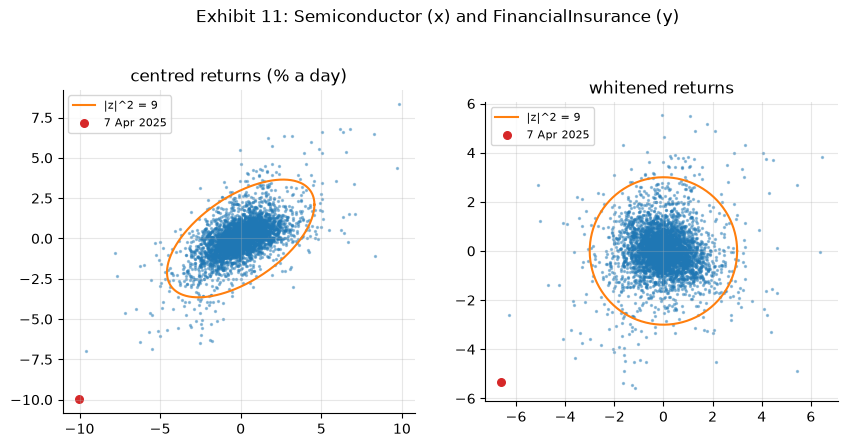

In [18]:
L2 = np.linalg.cholesky(Sig[np.ix_(i5[:2], i5[:2])])
Z2 = np.linalg.solve(L2, Xc[:, i5[:2]].T).T
print("the pair's z equals the first two entries of S5's z:", np.allclose(Z2, Z5[:, :2]))
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
t = np.linspace(0, 2 * np.pi, 400)
ring = np.vstack([np.cos(t), np.sin(t)]) * 3
for ax, P, curve, title in ((axes[0], 100 * Xc[:, i5[:2]], 100 * L2 @ ring, "centred returns (% a day)"),
                            (axes[1], Z2, ring, "whitened returns")):
    ax.scatter(P[:, 0], P[:, 1], s=2, alpha=0.4)
    ax.plot(curve[0], curve[1], color="tab:orange", label="|z|^2 = 9")
    ax.scatter([P[i7, 0]], [P[i7, 1]], color="tab:red", s=30, label="7 Apr 2025")
    ax.set_aspect("equal"); ax.set_title(title); ax.legend(fontsize=8)
fig.suptitle("Exhibit 11: Semiconductor (x) and FinancialInsurance (y)"); plt.show()

In [19]:
# colouring: L maps vectors with identity sample covariance to vectors with sample covariance Sigma
W = Z5 @ L5.T                       # rows L z_t, back to the centred returns
print(f"colouring the whitened returns gives back the centred returns: largest difference {np.abs(W - Xc[:, i5]).max():.1e}")

colouring the whitened returns gives back the centred returns: largest difference 1.4e-17


## Part 7 — Practice problems

Problems 1 and 2 are conceptual; the numerical parts of Problems 3–12 follow.

In [20]:
for name, Mx in (("A", [[4, 2], [2, 5]]), ("B", [[4, 6], [6, 9]]), ("C", [[1, 3], [3, 4]])):
    Mx = np.array(Mx, dtype=float)
    try:
        print(f"P3 matrix {name}: det {np.linalg.det(Mx):.0f}, L = {np.linalg.cholesky(Mx).tolist()}")
    except np.linalg.LinAlgError:
        print(f"P3 matrix {name}: det {np.linalg.det(Mx):.0f}, no Cholesky factor")

xp, yp = np.array([-1.0, 0, 1, 2]), np.array([0.0, 1, 1, 4])
Dp = np.column_stack([np.ones(4), xp]); bp = np.linalg.lstsq(Dp, yp, rcond=None)[0]; ep = yp - Dp @ bp
print(f"P4: alpha {bp[0]:.1f}, beta {bp[1]:.1f}, residuals {ep.round(1)}, sum {ep.sum():.1e}, x'e {xp @ ep:.1e}, "
      f"R-squared {1 - ep @ ep / ((yp - yp.mean()) ** 2).sum():.1f}")

x5 = np.array([[1.0], [1.0], [0.0]]); P5 = x5 @ x5.T / 2
print(f"P5: Pi = {P5.tolist()}, |Pi Pi - Pi| = {np.abs(P5 @ P5 - P5).max()}, trace {np.trace(P5)}, Pi y = {P5 @ [3, 1, 2]}")

M6 = np.array([[2.0, 0.0], [3.0, 2.0]]); _, s6, V6 = np.linalg.svd(M6)
v6 = [sign_rule(r) for r in V6]
print(f"P6: s = {s6}, v_k * sqrt(5) = {(np.array(v6) * math.sqrt(5)).round(6).tolist()}, "
      f"u_k * sqrt(5) = {(np.array([M6 @ v6[k] / s6[k] for k in range(2)]) * math.sqrt(5)).round(6).tolist()}, kappa {s6[0] / s6[1]:.0f}")

M7 = np.array([[1.0, 2.0], [2.0, 4.0]])
print(f"P7: pinv * 25 = {(np.linalg.pinv(M7) * 25).round(9).tolist()}, minimum-norm solution {np.linalg.pinv(M7) @ [5, 10]}")

P3 matrix A: det 16, L = [[2.0, 0.0], [1.0, 2.0]]
P3 matrix B: det 0, no Cholesky factor
P3 matrix C: det -5, no Cholesky factor
P4: alpha 0.9, beta 1.2, residuals [ 0.3  0.1 -1.1  0.7], sum 0.0e+00, x'e 1.1e-15, R-squared 0.8
P5: Pi = [[0.5, 0.5, 0.0], [0.5, 0.5, 0.0], [0.0, 0.0, 0.0]], |Pi Pi - Pi| = 0.0, trace 1.0, Pi y = [2. 2. 0.]
P6: s = [4. 1.], v_k * sqrt(5) = [[2.0, 1.0], [-1.0, 2.0]], u_k * sqrt(5) = [[1.0, 2.0], [-2.0, 1.0]], kappa 4
P7: pinv * 25 = [[1.0, 2.0], [2.0, 4.0]], minimum-norm solution [1. 2.]


In [21]:
s5 = np.linalg.svd(Xc[:, i5] / math.sqrt(T), compute_uv=False)
print("P8: singular values", s5.round(6), " eigenvalues x 1e4", (1e4 * s5 ** 2).round(3),
      f" kappa(X~) {s5[0] / s5[-1]:.3f}, kappa(Sigma) {(s5[0] / s5[-1]) ** 2:.2f}")

s1, s2, rho = 0.201, 0.135, -0.11
S7 = np.array([[s1 ** 2, rho * s1 * s2], [rho * s1 * s2, s2 ** 2]])
L7 = np.linalg.cholesky(S7)
print(f"P9: L = {L7.round(5).tolist()}, slope l21/l11 = {L7[1, 0] / L7[0, 0]:.4f}, l22 = {L7[1, 1]:.4%}")
d = np.array([-0.30, 0.10])
z = np.linalg.solve(L7, d)
zr = np.linalg.solve(np.linalg.cholesky(S7[::-1, ::-1]), d[::-1])
print(f"P10: z = {z.round(4)}, |z|^2 = {z @ z:.3f}; reversed order z = {zr.round(4)}, |z|^2 = {zr @ zr:.3f}; "
      f"d' Sigma^-1 d = {d @ np.linalg.solve(S7, d):.3f}")

P8: singular values [0.02424  0.013487 0.01147  0.009351 0.006964]  eigenvalues x 1e4 [5.876 1.819 1.316 0.874 0.485]  kappa(X~) 3.481, kappa(Sigma) 12.12
P9: L = [[0.201, 0.0], [-0.01485, 0.13418]], slope l21/l11 = -0.0739, l22 = 13.4181%
P10: z = [-1.4925  0.5801], |z|^2 = 2.564; reversed order z = [ 0.7407 -1.4197], |z|^2 = 2.564; d' Sigma^-1 d = 2.564


In [22]:
# P11: the last-250 fit three ways
XL = X[LAST] - X[LAST].mean(axis=0); yL = y[LAST] - y[LAST].mean()
b_a = np.linalg.lstsq(np.column_stack([np.ones(250), X[LAST]]), y[LAST], rcond=None)[0][1:]
b_b = np.linalg.solve(XL.T @ XL, XL.T @ yL)
b_c = (np.linalg.pinv(np.column_stack([np.ones(250), X[LAST]])) @ y[LAST])[1:]
sL = np.linalg.svd(XL, compute_uv=False)
print(f"P11: R-squared {r2_last:.5f}; largest gaps {np.abs(b_a - b_b).max():.1e} and {np.abs(b_a - b_c).max():.1e}; "
      f"kappa(X~) {sL[0] / sL[-1]:.2f}, kappa(X~'X~) {(sL[0] / sL[-1]) ** 2:.1f}")
# P12: yearly fits and the numerical rank of Electronic + eight at delta = 0.01
ranks = {yr: (int((ratios(year == yr) > 0.01).sum()),
              int(np.linalg.matrix_rank((E9[year == yr] - E9[year == yr].mean(0)) / E9[year == yr].std(0))))
         for yr in range(2009, 2027)}
print(f"P12: smallest yearly R-squared {low['R-squared']:.5f} ({low['year']}); rank at 0.01 and matrix_rank by year:", ranks)

P11: R-squared 0.99912; largest gaps 1.9e-15 and 2.7e-16; kappa(X~) 17.04, kappa(X~'X~) 290.2
P12: smallest yearly R-squared 0.99800 (2021); rank at 0.01 and matrix_rank by year: {2009: (9, 9), 2010: (9, 9), 2011: (8, 9), 2012: (8, 9), 2013: (8, 9), 2014: (8, 9), 2015: (8, 9), 2016: (8, 9), 2017: (8, 9), 2018: (9, 9), 2019: (8, 9), 2020: (8, 9), 2021: (8, 9), 2022: (8, 9), 2023: (8, 9), 2024: (8, 9), 2025: (8, 9), 2026: (8, 9)}


### Extension: how close is a coloured simulation?

Colour $T$ independent standard normal draws with S5's $L$ and compare the sample covariance of the simulated returns with $\hat\Sigma$. The relative gap below uses the Frobenius norm, the square root of the sum of squared entries. Then repeat with other seeds and with $T$ = 500, 4,382 and 50,000: how does the gap shrink as $T$ grows? [[LM18]] explains the rate.

In [23]:
rng = np.random.default_rng(20261011)
draws = rng.standard_normal((T, 5))
sim = draws @ L5.T                      # row t is L z_t
S_sim = np.cov(sim, rowvar=False, ddof=0)
gap = np.linalg.norm(S_sim - S5m) / np.linalg.norm(S5m)
print(f"relative Frobenius gap: {gap:.4f}")
show("relative Frobenius gap (4 decimals)", gap, ".4f", "0.0250")
# your code: other seeds, other T

relative Frobenius gap: 0.0250
relative Frobenius gap (4 decimals): 0.0250   [book: 0.0250]
